
dataset_path = "/content/drive/MyDrive/seatbelt and Mobile"

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [ ]:
data_dir = '/content/drive/MyDrive/seatbelt_dataset_1K' # <<-- Edit this to your actual directory

train_csv_path = os.path.join(data_dir, "train", "labels.csv")
valid_csv_path = os.path.join(data_dir, "valid", "labels.csv")


IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 12

In [ ]:
data_dir = "/content/drive/MyDrive/seatbelt_dataset_1K"

# Paths to CSVs
train_csv_path = os.path.join(data_dir, "train", "labels.csv")
valid_csv_path = os.path.join(data_dir, "valid", "labels.csv")

# Load CSVs
train_df = pd.read_csv(train_csv_path)
valid_df = pd.read_csv(valid_csv_path)

print("Train CSV head:\n", train_df.head())
print("Valid CSV head:\n", valid_df.head())

# Now add absolute image paths
def add_image_paths(df, split):
    df = df.copy()
    base_split_dir = os.path.join(data_dir, split)
    img_dir_with_sub = os.path.join(base_split_dir, "images")

    if os.path.exists(img_dir_with_sub) and os.path.isdir(img_dir_with_sub):
        img_dir = img_dir_with_sub
    else:
        # Fallback: assume images are directly in the split directory
        img_dir = base_split_dir

    # Here, the filename column is literally named "filename"
    df["filepath"] = df["filename"].apply(lambda x: os.path.join(img_dir, str(x)))
    df["label"] = df["seatbelt"].astype(str)   # use the 'class' column as the label
    return df[["filepath", "label"]]

train_df = add_image_paths(train_df, "train")
valid_df = add_image_paths(valid_df, "valid")

print(train_df.head())
print(valid_df.head())



# sanity check
print(train_df["filepath"].iloc[0])
print(os.path.exists(train_df["filepath"].iloc[0]))

Train CSV head:
   filename  width  height seatbelt
0  001.jpg    590     600      yes
1  002.jpg    508     579      yes
2  003.jpg    540     490      yes
3  004.jpg    572     579      yes
4  005.jpg    605     577       no
Valid CSV head:
    filename  width  height seatbelt
0  img1.jpg    576     559      yes
1  img2.jpg    574     617      yes
2  img3.jpg    554     567       no
3  img4.jpg    586     528       no
4  img5.jpg    581     572       no
                                            filepath label
0  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
1  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
2  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
3  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
4  /content/drive/MyDrive/seatbelt_dataset_1K/tra...    no
                                            filepath label
0  /content/drive/MyDrive/seatbelt_dataset_1K/val...   yes
1  /content/drive/MyDrive/seatbelt_dataset_1K/val...   yes
2  /conte

In [ ]:

# 4) Normalize column names and create absolute filepath column
# This block tries to detect likely column names and normalize them to 'filepath' and 'label'

def ensure_filepath_label_columns(df, data_dir):
    df = df.copy()
    # Possible filename columns
    filename_cols = [c for c in df.columns if c.lower() in ('filename', 'file', 'file_name', 'filepath', 'image', 'image_path')]
    label_cols = [c for c in df.columns if c.lower() in ('label', 'labels', 'seatbelt', 'target')]

    if not filename_cols:
        raise ValueError('No filename column found in CSV. Expected one of: filename, file, file_name, filepath, image, image_path')
    if not label_cols:
        raise ValueError('No label column found in CSV. Expected one of: label, labels, class, target')

    fname_col = filename_cols[0]
    lab_col = label_cols[0]

    # create absolute path
    def make_path(x):
        if os.path.isabs(x):
            return x
        return os.path.join(data_dir, str(x))

    df['filepath'] = df[fname_col].apply(make_path)
    df['label'] = df[lab_col].astype(str)
    return df[['filepath', 'label']]

train_df = ensure_filepath_label_columns(train_df, data_dir)
valid_df = ensure_filepath_label_columns(valid_df, data_dir)

print(train_df.head())



                                            filepath label
0  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
1  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
2  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
3  /content/drive/MyDrive/seatbelt_dataset_1K/tra...   yes
4  /content/drive/MyDrive/seatbelt_dataset_1K/tra...    no


In [ ]:
# %%
# 5) Build label mapping (string -> int) and apply
labels = sorted(train_df['label'].unique().tolist())
label_to_idx = {l: i for i, l in enumerate(labels)}
idx_to_label = {i: l for l, i in label_to_idx.items()}

train_df['label_idx'] = train_df['label'].map(label_to_idx)
valid_df['label_idx'] = valid_df['label'].map(label_to_idx)

print('Classes:', label_to_idx)


Classes: {'no': 0, 'yes': 1}


In [ ]:

# %%
# 6) tf.data pipeline helpers

def decode_and_resize(filename, label):
    image = tf.io.read_file(filename)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0  # normalize to [0,1]
    return image, label


def random_augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, 0.9, 1.1)
    return image, label


def make_dataset(filepaths, labels, training=True):
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(filepaths))
    ds = ds.map(lambda f, l: decode_and_resize(f, l), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(random_augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df['filepath'].values, train_df['label_idx'].values, training=True)
valid_ds = make_dataset(valid_df['filepath'].values, valid_df['label_idx'].values, training=False)


In [ ]:
# %%
# 7) Create model (transfer learning with MobileNetV2 backbone)

base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
base_model.trainable = False  # freeze base

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(labels), activation='softmax')(x)
model = models.Model(inputs, outputs)

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()



9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# 8) Callbacks and training
checkpoint_path = os.path.join(data_dir, 'best_model.h5')
callbacks = [
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks)



Epoch 1/12


NotFoundError: Graph execution error:

Detected at node ReadFile defined at (most recent call last):
<stack traces unavailable>
Error in user-defined function passed to ParallelMapDatasetV2:2 transformation with iterator: Iterator::Root::Prefetch::MapAndBatch::ParallelMapV2: /content/drive/MyDrive/seatbelt_dataset_1K/train/images/177.jpg; No such file or directory
	 [[{{node ReadFile}}]]
	 [[IteratorGetNext]] [Op:__inference_multi_step_on_iterator_23247]

In [ ]:
# %%
# 9) Unfreeze some layers and fine-tune (optional)

base_model.trainable = True
# Fine-tune from a specific layer
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

fine_history = model.fit(train_ds, validation_data=valid_ds, epochs=5, callbacks=callbacks)



Epoch 1/5


NotFoundError: Graph execution error:

Detected at node ReadFile defined at (most recent call last):
<stack traces unavailable>
Error in user-defined function passed to ParallelMapDatasetV2:2 transformation with iterator: Iterator::Root::Prefetch::MapAndBatch::ParallelMapV2: /content/drive/MyDrive/seatbelt_dataset_1K/train/images/310.jpg; No such file or directory
	 [[{{node ReadFile}}]]
	 [[IteratorGetNext]] [Op:__inference_multi_step_on_iterator_23247]

/usr/local/lib/python3.12/dist-packages/keras/src/legacy/saving/legacy_h5_format.py:513: UserWarning: Skipping loading weights for layer #1 (named mobilenetv2_1.00_224)due to mismatch in shape for weight block_11_depthwise/kernel. Weight expects shape (3, 3, 576, 1). Received saved weight with shape (3, 3, 3, 32)
  _set_weights(
/usr/local/lib/python3.12/dist-packages/keras/src/legacy/saving/legacy_h5_format.py:513: UserWarning: Skipping loading weights for layer #1 (named mobilenetv2_1.00_224)due to mismatch in shape for weight block_11_depthwise_BN/gamma. Weight expects shape (576,). Received saved weight with shape (32,)
  _set_weights(
/usr/local/lib/python3.12/dist-packages/keras/src/legacy/saving/legacy_h5_format.py:513: UserWarning: Skipping loading weights for layer #1 (named mobilenetv2_1.00_224)due to mismatch in shape for weight block_11_depthwise_BN/beta. Weight expects shape (576,). Received saved weight with shape (32,)
  _set_weights(
/usr/local/lib/python3.12/dist-packa

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1000ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 994ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step


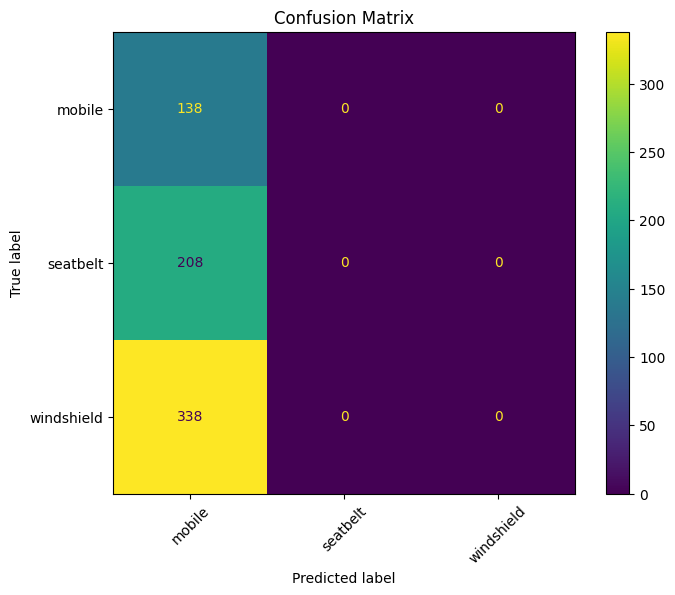

In [ ]:
if os.path.exists(checkpoint_path):
    model.load_weights(checkpoint_path, by_name=True, skip_mismatch=True)


y_true, y_pred = [], []
for images, labels_batch in valid_ds:
    preds = model.predict(images)
    preds_idx = np.argmax(preds, axis=1)
    y_true.extend(labels_batch.numpy().tolist())
    y_pred.extend(preds_idx.tolist())

# print("Classification report:")
# print(classification_report(y_true, y_pred, target_names=labels))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, xticks_rotation=45)
plt.title('Confusion Matrix')
plt.show()


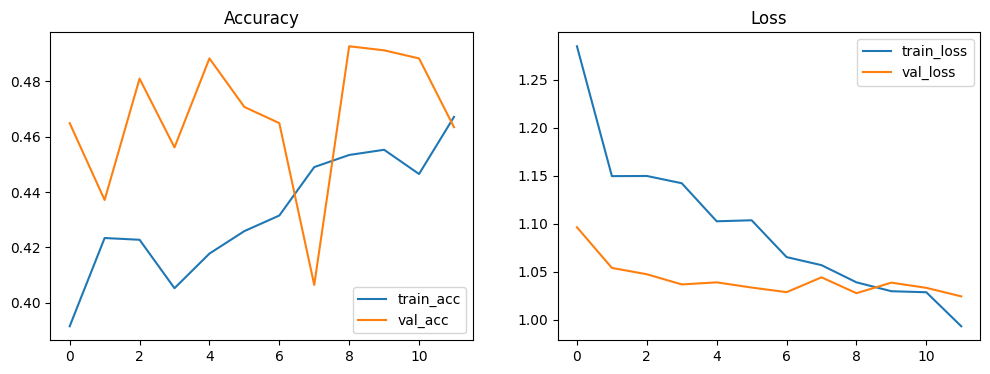

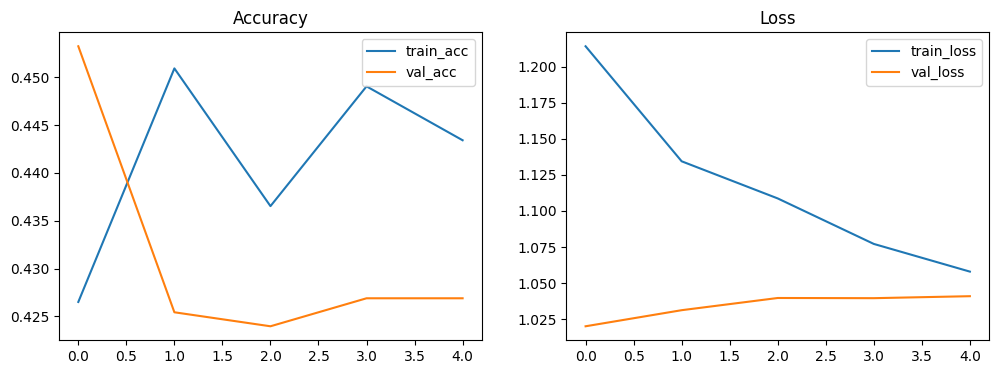

In [ ]:
def plot_history(h, title='Model accuracy & loss'):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['accuracy'], label='train_acc')
    ax[0].plot(h.history['val_accuracy'], label='val_acc')
    ax[0].set_title('Accuracy')
    ax[0].legend()

    ax[1].plot(h.history['loss'], label='train_loss')
    ax[1].plot(h.history['val_loss'], label='val_loss')
    ax[1].set_title('Loss')
    ax[1].legend()
    plt.show()

plot_history(history)
plot_history(fine_history)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
print(f"Current data_dir: {data_dir}")
!ls -R "{data_dir}"

Current data_dir: /content/drive/MyDrive/seatbelt_dataset_1K
/content/drive/MyDrive/seatbelt_dataset_1K:
README.dataset.txt  README.roboflow.txt  train	valid

/content/drive/MyDrive/seatbelt_dataset_1K/train:
labels.csv  main_labels.csv

/content/drive/MyDrive/seatbelt_dataset_1K/valid:
images	labels.csv  labels_dup.csv

/content/drive/MyDrive/seatbelt_dataset_1K/valid/images:
img100.jpg  img152.jpg	img203.jpg  img255.jpg	img306.jpg  img53.jpg
img101.jpg  img153.jpg	img204.jpg  img256.jpg	img307.jpg  img54.jpg
img102.jpg  img154.jpg	img205.jpg  img257.jpg	img308.jpg  img55.jpg
img103.jpg  img155.jpg	img206.jpg  img258.jpg	img309.jpg  img56.jpg
img104.jpg  img156.jpg	img207.jpg  img259.jpg	img30.jpg   img57.jpg
img105.jpg  img157.jpg	img208.jpg  img25.jpg	img310.jpg  img58.jpg
img106.jpg  img158.jpg	img209.jpg  img260.jpg	img311.jpg  img59.jpg
img107.jpg  img159.jpg	img20.jpg   img261.jpg	img312.jpg  img5.jpg
img108.jpg  img15.jpg	img210.jpg  img262.jpg	img313.jpg  img60.jpg
img109.jpg 

In [ ]:
!pip install twilio



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.8 MB/s eta 0:00:00


In [ ]:
import os
from twilio.rest import Client

def send_alert_sms(owner_phone, vehicle_number):
    account_sid = os.getenv("TWILIO_ACCOUNT_SID")
    auth_token = os.getenv("TWILIO_AUTH_TOKEN")
    client = Client(account_sid, auth_token)

    message = client.messages.create(
        body=f"⚠️ Alert: Seatbelt not detected for Vehicle {vehicle_number}. Please ensure driver safety.",
        from_=os.getenv("TWILIO_FROM_NUMBER"),  # your Twilio number
        to=owner_phone
    )

    print("SMS sent:", message.sid)


In [ ]:
# (credential removed)

send_alert_sms("+91 8639142276", "AP 39 XX 1234")

SMS sent: SMc2f7774f7241c4dcd2ce607f489ed61a
